In [1]:
#geospatial clustering for developing separate rf models for each region
#clusters based on relationship of predictor variables with precipitation (target variable)
#we use stable climatology (30yrs) of predictor variables and precipitation(HAR)
#resample all variables to common grid (1km)
#fit rf models to derive weights of each predictor variable to precipitation
#perform weighted k means clustering 
#optimum cluster determined by elbow + shiloutte method

In [2]:
import os
import glob
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import rioxarray as rxr
import xarray as xr
import matplotlib.pyplot as plt
import dask

In [ ]:
#create precipitation climatology using har
har_files_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\HAR_prec"
har_files = sorted(glob.glob(os.path.join(har_files_path, "*.tif")))
har_dates = [pd.to_datetime(f[-12:-4], format='%Y%m%d') for f in har_files]

har_files_rxr = xr.concat([rxr.open_rasterio(f, chunks={'x': 512, 'y': 512}) for f in har_files], 
               dim=pd.Index(har_dates, name='time'))

# prec_climatology = har_files_rxr.resample(time='1YE').sum().mean(dim='time')
# prec_climatology   

In [ ]:
prec_climatology = har_files_rxr.resample(time = '1YE').sum()
# mean(dim = 'time')
prec_climatology

<xarray.DataArray (band: 1, y: 48, x: 94)> Size: 18kB
dask.array<mean_agg-aggregate, shape=(1, 48, 94), dtype=float32, chunksize=(1, 48, 94), chunktype=numpy.ndarray>
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 384B 30.69 30.59 30.49 30.4 ... 26.25 26.15 26.05
  * x            (x) float64 752B 79.5 79.6 79.7 79.79 ... 88.48 88.58 88.68
    spatial_ref  int64 8B 0
Attributes:
    agg_method:     mean
    long_name:      total precipitation (step-wize)
    units:          mm h-1
    AREA_OR_POINT:  Area
    _FillValue:     nan
    scale_factor:   1.0
    add_offset:     0.0

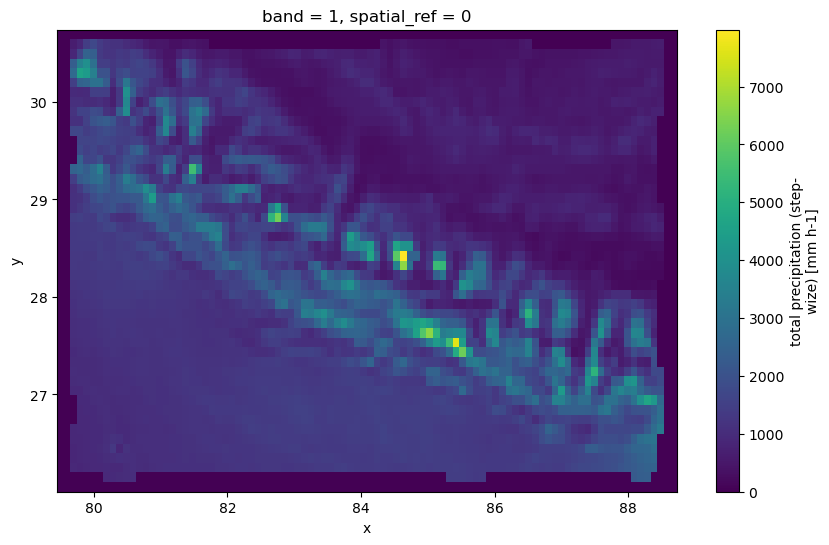

In [14]:
plt.figure(figsize=(10, 6))
prec_climatology.plot()

In [ ]:
#read all predictor and target variables

#Static variables - already single image files at 1km resolution

#Fetch Variables - fetch distance and direction to nearest ridge >500m and >1000m
fetch_dist_500m_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch_Variables\fetch_dist_500m_upscaled.tif"
fetch_dir_500m_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch_Variables\fetch_dir_500m_upscaled.tif"
fetch_dist_1000m_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch_Variables\fetch_dist_1000m_upscaled.tif"
fetch_dir_1000m_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Processed\Fetch_Variables\fetch_dir_1000m_upscaled.tif"

#dem variables - elevation_mean, elevation_max, elevation_min, slope_mean, aspect_mean, elevation_std
slope_mean_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\DEM_1km\DEM_1km_slope_mean.tif"
aspect_mean_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\DEM_1km\DEM_1km_aspect_mean.tif"
elevation_mean_path = r"C:\Users\A S U S\Documents\Study\Study\ClimateData\CD-Workspace\Data\Datasets\DEM_1km\DEM_1km_elevation_mean.tif"
elevation_max_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\DEM_1km\DEM_1km_elevation_max.tif"
elevation_min_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\DEM_1km\DEM_1km_elevation_min.tif"
elevation_std_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\DEM_1km\DEM_1km_elevation_std.tif"


